<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="assets/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **Practice Assignment - Part 1: Analyzing wildfire activities in Australia** 

Estimated time needed: **40** minutes


# __Table of Contents__

<ol>
    <li><a href="#Objectives">Objectives</a></li>
    <li>
        <a href="#Setup">Setup</a>
        <ol>
            <li><a href="#Installing-Required-Libraries">Installing Required Libraries</a></li>
            <li><a href="#Importing-Required-Libraries">Importing Required Libraries</a></li>
    </li>
    <li>
        <a href="#Dataset">Dataset</a>
    </li>
    <li><a href="#Importing Dataset">Importing Dataset</a></li>
    <li><a href="#Practice Tasks">Practice Tasks</a></li>
   


---


# Objectives

After completing this lab you will be able to:

 - Use visualization libraries such as Matplotlib, Pandas, Seaborn and Folium to create informative plots and charts 


---


# Setup


For this lab, we will be using the following libraries:

*   [`pandas`](https://pandas.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for managing the data.
*   [`numpy`](https://numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for mathematical operations.
*   [`seaborn`](https://seaborn.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for visualizing the data.
*   [`matplotlib`](https://matplotlib.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for additional plotting tools.


### Installing Required Libraries

The following required libraries are pre-installed in the Skills Network Labs environment. However, if you run this notebook commands in a different Jupyter environment (e.g. Watson Studio or Ananconda), you will need to install these libraries by removing the `#` sign before `%pip` in the code cell below.


In [1]:
from IPython.display import display
%matplotlib inline
# All Libraries required for this lab are listed below. The libraries pre-installed on Skills Network Labs are commented.
#%pip install -qy pandas==1.3.4 numpy==1.21.4 seaborn==0.9.0 matplotlib==3.5.0 folium
# Note: If your environment doesn't support "%pip install", use "!mamba install"

In [2]:
# Required libraries are already installed in this local environment
# (pandas, numpy, matplotlib, seaborn, folium).

### Importing Required Libraries

_We recommend you import all required libraries in one place (here):_


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
%matplotlib inline

---


# Dataset

**Historical Wildfires**

This wildfire dataset contains data on fire activities in Australia starting from 2005. Additional information can be found [here](https://earthdata.nasa.gov/earth-observation-data/near-real-time/firms/c6-mcd14dl).

Variables

- Region: the 7 regions
- Date: in UTC and provide the data for 24 hours ahead
- Estimated_fire_area: daily sum of estimated fire area for presumed vegetation fires with a confidence > 75% for a each region in km2
- Mean_estimated_fire_brightness: daily mean (by flagged fire pixels(=count)) of estimated fire brightness for presumed vegetation fires with a confidence level > 75% in Kelvin
- Mean_estimated_fire_radiative_power: daily mean of estimated radiative power for presumed vegetation fires with a confidence level > 75% for a given region in megawatts
- Mean_confidence: daily mean of confidence for presumed vegetation fires with a confidence level > 75%
- Std_confidence: standard deviation of estimated fire radiative power in megawatts
- Var_confidence: Variance of estimated fire radiative power in megawatts
- Count: daily numbers of pixels for presumed vegetation fires with a confidence level of larger than 75% for a given region
- Replaced: Indicates with an Y whether the data has been replaced with standard quality data when they are available (usually with a 2-3 month lag). Replaced data has a slightly higher quality in terms of locations


---


### Importing Data


In [4]:
import pandas as pd
df = pd.read_csv('data/Historical_Wildfires.csv')
print('Local data read into a pandas dataframe!')


Local data read into a pandas dataframe!


Let's look at some samples rows from the dataset we loaded:


In [5]:
df.head()

,Region,Date,Estimated_fire_area,Mean_estimated_fire_brightness,Mean_estimated_fire_radiative_power,Mean_confidence,Std_confidence,Var_confidence,Count,Replaced
0,NSW,1/4/2005,8.68000,312.266667,42.400000,78.666667,2.886751,8.333333,3,R
1,NSW,1/5/2005,16.61125,322.475000,62.362500,85.500000,8.088793,65.428571,8,R
2,NSW,1/6/2005,5.52000,325.266667,38.400000,78.333333,3.214550,10.333333,3,R
3,NSW,1/7/2005,6.26400,313.870000,33.800000,92.200000,7.529940,56.700000,5,R
4,NSW,1/8/2005,5.40000,337.383333,122.533333,91.000000,7.937254,63.000000,3,R


---


Let's verify the column names and the data type of each variable


In [6]:
#Column names
df.columns

Index(['Region', 'Date', 'Estimated_fire_area',
       'Mean_estimated_fire_brightness', 'Mean_estimated_fire_radiative_power',
       'Mean_confidence', 'Std_confidence', 'Var_confidence', 'Count',
       'Replaced'],
      dtype='str')

In [7]:
#data type
df.dtypes

Region                                     str
Date                                       str
Estimated_fire_area                    float64
Mean_estimated_fire_brightness         float64
Mean_estimated_fire_radiative_power    float64
Mean_confidence                        float64
Std_confidence                         float64
Var_confidence                         float64
Count                                    int64
Replaced                                   str
dtype: object

Notice the type of 'Date' is object, let's convert it to 'datatime' type and also let's extract 'Year' and 'Month' from date and include in the dataframe as separate columns


In [8]:
dates = pd.to_datetime(df['Date'], format='%m/%d/%Y')
df['Year'] = dates.dt.year
df['Month'] = dates.dt.month

**Verify the columns again**


In [9]:
df[['Date', 'Year', 'Month']].head()

,Date,Year,Month
0,1/4/2005,2005,1
1,1/5/2005,2005,1
2,1/6/2005,2005,1
3,1/7/2005,2005,1
4,1/8/2005,2005,1


<details>
    <summary>Click here for Solution</summary>

```python
    df.dtypes
```

</details>


---


## Practice Tasks


### TASK 1.1: Let's try to understand the change in average estimated fire area over time <br>(use pandas to plot)


<details>
    <summary>Click here for a Hint</summary>
You will be required to group the year for 'Estimated_fire_area' (taking its mean)<br>Then use df.plot() on it to create a line graph

</details>


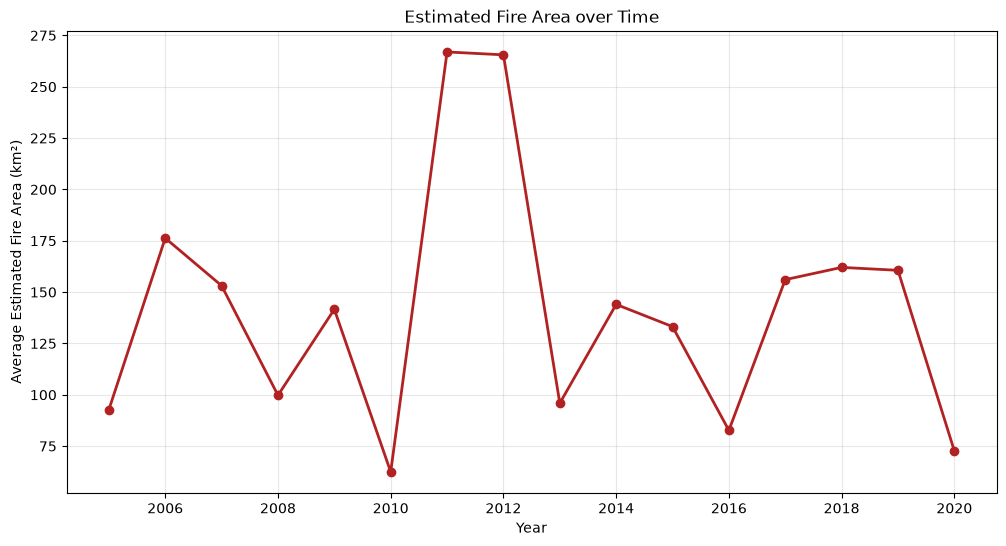

Highest yearly means:
Year
2011    266.94
2012    265.53
2006    176.29
Name: Estimated_fire_area, dtype: float64


In [10]:
# TASK 1.1 - Average estimated fire area over time (pandas line plot)
plt.figure(figsize=(12, 6))
# Grouping the data by 'Year' and calculating the mean of 'Estimated_fire_area'
df_new = df.groupby('Year')['Estimated_fire_area'].mean()
# Plotting the data
df_new.plot(x=df_new.index, y=df_new.values, marker='o', linewidth=2, color='firebrick')
plt.xlabel('Year')
plt.ylabel('Average Estimated Fire Area (km²)')
plt.title('Estimated Fire Area over Time')
plt.grid(alpha=0.3)
plt.show()

# Two troughs (2010, 2016) and one clear peak: 2011-2012 (~266 km²)
print('Highest yearly means:')
print(df_new.sort_values(ascending=False).head(3).round(2))

<details>
    <summary>Click here for Solution</summary>

```python
    plt.figure(figsize=(12, 6))
    # Grouping the data by 'Year' and calculating the mean of 'Estimated_fire_area'
    df_new = df.groupby('Year')['Estimated_fire_area'].mean()
    # Plotting the data
    df_new.plot(x=df_new.index, y=df_new.values)
    plt.xlabel('Year')
    plt.ylabel('Average Estimated Fire Area (km²)')
    plt.title('Estimated Fire Area over Time')
    plt.show()
```

</details>


---


### TASK 1.2: You can notice the peak in the plot between 2010 to 2013. Let's narrow down our finding, by plotting the estimated fire area for year grouped together with month.


<details>
    <summary>Click here for a Hint</summary>
You will be required to group the year and month for 'Estimated_fire_area' (taking its mean)<br>Then use df.plot() on it to create a line graph

</details>


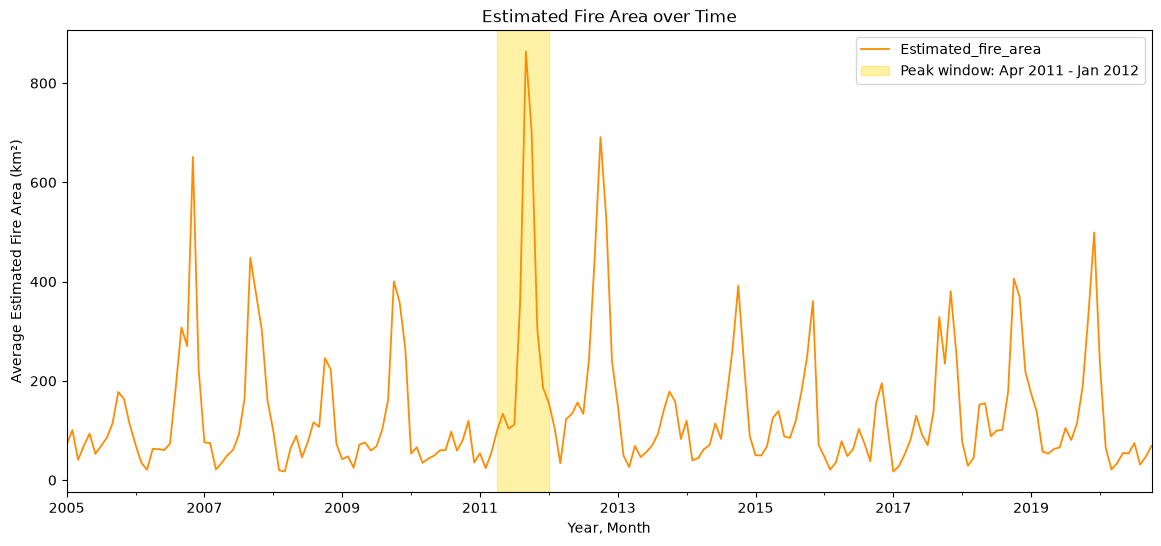

Peak month : 2011-09 | mean area = 863.79 km²


In [11]:
# TASK 1.2 - Year and Month grouped together to zoom into the 2010-2013 peak
plt.figure(figsize=(14, 6))
# Grouping the data by both 'Year' and 'Month', and calculating the mean of 'Estimated_fire_area'
df_new = df.groupby(['Year', 'Month'])['Estimated_fire_area'].mean()
# Turn the (Year, Month) MultiIndex into a real time axis so the line is readable
df_new.index = pd.to_datetime([f'{y}-{m:02d}-01' for y, m in df_new.index])

df_new.plot(x=df_new.index, y=df_new.values, linewidth=1.3, color='darkorange')
# Highlight the window identified above
plt.axvspan(pd.Timestamp('2011-04-01'), pd.Timestamp('2012-01-01'),
            color='gold', alpha=0.35, label='Peak window: Apr 2011 - Jan 2012')
plt.xlabel('Year, Month')
plt.ylabel('Average Estimated Fire Area (km²)')
plt.title('Estimated Fire Area over Time')
plt.legend()
plt.show()

peak = df_new.idxmax()
print('Peak month :', peak.strftime('%Y-%m'), '| mean area =', round(df_new.max(), 2), 'km²')

<details>
    <summary>Click here for Solution</summary>

```python
    # Grouping the data by both 'Year' and 'Month', and calculating the mean of 'Estimated_fire_area'
    df_new = df.groupby(['Year','Month'])['Estimated_fire_area'].mean()
    # Plotting the data
    df_new.plot(x=df_new.index, y=df_new.values)
    plt.xlabel('Year, Month')
    plt.ylabel('Average Estimated Fire Area (km²)')
    plt.title('Estimated Fire Area over Time')
    plt.show()
```

</details>


This plot represents that the estimated fire area was on its peak after 2011, April and before 2012. You can verify on google/news, this was the time of maximum wildfire hit in Austrailia


---


### TASK 1.3: Let's have an insight on the distribution of mean estimated fire brightness across the regions<br> use the functionality of seaborn to develop a barplot


before starting with the plot, why not know the regions mentioned in the dataset?. <br>Make use of unique() to identify the regions in the dataset (apply it on series only)


In [12]:
# TASK 1.3 (part 1) - inspect the regions present in the dataset
df['Region'].unique()

<StringArray>
['NSW', 'NT', 'QL', 'SA', 'TA', 'VI', 'WA']
Length: 7, dtype: str

<details>
    <summary>Click here for a Hint</summary>
you need to plot reions on x-axis and the 'Mean_estimated_fire_brightness' on y-axis.<br>Title it as 'Distribution of Mean Estimated Fire Brightness across Regions'
</details>


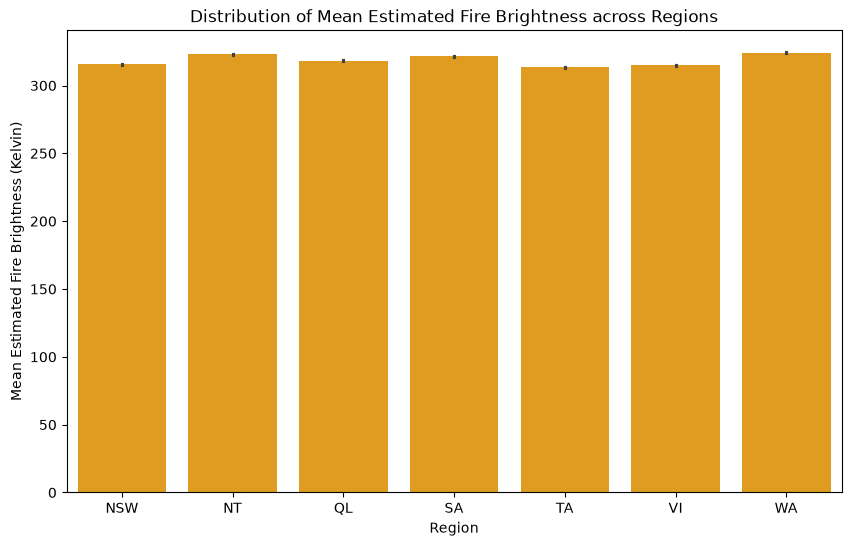

Region
NSW    315.53
NT     322.90
QL     318.36
SA     321.50
TA     313.37
VI     315.03
WA     324.14
Name: Mean_estimated_fire_brightness, dtype: float64
Range across regions: 10.77 K


In [13]:
# TASK 1.3 (part 2) - bar plot of mean estimated fire brightness across regions
plt.figure(figsize=(10, 6))
# Using seaborn's barplot function to create the plot
sns.barplot(data=df, x='Region', y='Mean_estimated_fire_brightness', color='orange')
plt.xlabel('Region')
plt.ylabel('Mean Estimated Fire Brightness (Kelvin)')
plt.title('Distribution of Mean Estimated Fire Brightness across Regions')
plt.show()

# The bars are nearly flat: region explains very little of the brightness variance
stats = df.groupby('Region')['Mean_estimated_fire_brightness'].mean().round(2)
print(stats)
print('Range across regions:', round(stats.max() - stats.min(), 2), 'K')

<details>
    <summary>Click here for Solution</summary>

```python
# Creating a bar plot using seaborn to visualize the distribution of mean estimated fire brightness across regions
plt.figure(figsize=(10, 6))
# Using seaborn's barplot function to create the plot
sns.barplot(data=df, x='Region', y='Mean_estimated_fire_brightness')
plt.xlabel('Region')
plt.ylabel('Mean Estimated Fire Brightness (Kelvin)')
plt.title('Distribution of Mean Estimated Fire Brightness across Regions')
plt.show()
```
</details>


---


### TASK 1.4: Let's find the portion of count of pixels for presumed vegetation fires vary across regions<br> we will develop a pie chart for this


<details>
    <summary>Click here for a Hint</summary>
First you will  be required to group the data on region and find the sum of count
</details>


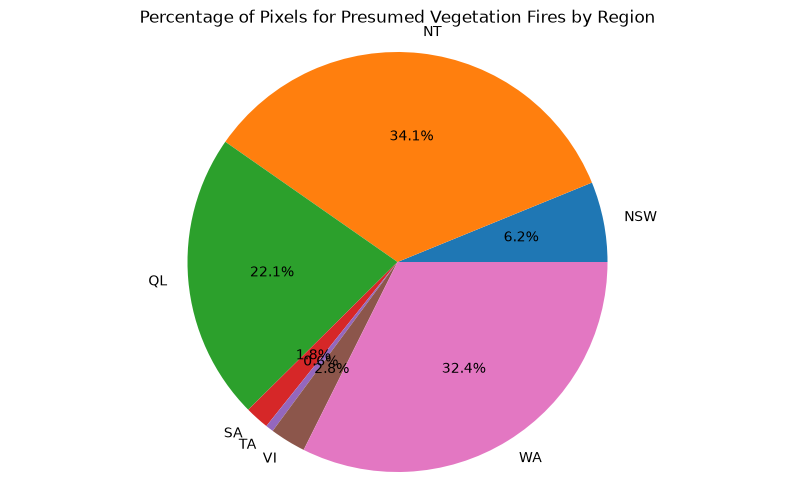

In [14]:
# TASK 1.4 - pie chart of the count of pixels for presumed vegetation fires per region
plt.figure(figsize=(10, 6))
# Grouping the data by region and summing the counts
region_counts = df.groupby('Region')['Count'].sum()
# Creating the pie chart using plt.pie function
# Labels are set to the region names, and autopct is used to display percentage
plt.pie(region_counts, labels=region_counts.index, autopct='%1.1f%%')
plt.title('Percentage of Pixels for Presumed Vegetation Fires by Region')
plt.axis('equal')
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
# Creating a pie chart to visualize the portion of count of pixels for presumed vegetation fires across regions
plt.figure(figsize=(10, 6))
# Grouping the data by region and summing the counts
region_counts = df.groupby('Region')['Count'].sum()
# Creating the pie chart using plt.pie function
# Labels are set to the region names, and autopct is used to display percentage
plt.pie(region_counts, labels=region_counts.index, autopct='%1.1f%%')
plt.title('Percentage of Pixels for Presumed Vegetation Fires by Region')
plt.axis('equal')
plt.show()
```
</details>


### TASK 1.5: See the percentage on the pie is not looking so good as it is overlaped for Region SA, TA, VI 

remove the autopct from pie function and pass the following to plt.legend() after plt.title() <br>
`[(i,round(k/region_counts.sum()*100,2)) for i,k in zip(region_counts.index, region_counts)]`


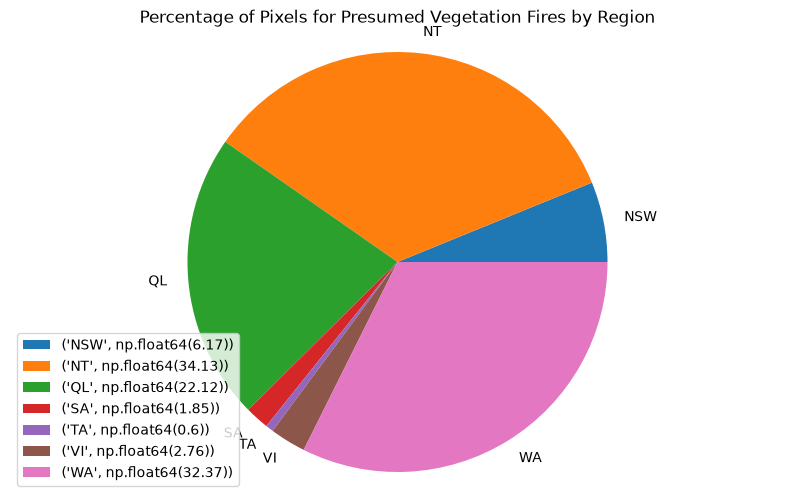

In [15]:
# TASK 1.5 - remove autopct (the small slices overlapped) and move the
# percentages into the legend instead
region_counts = df.groupby('Region')['Count'].sum()

plt.figure(figsize=(10, 6))
plt.pie(region_counts, labels=region_counts.index)          # no autopct
plt.title('Percentage of Pixels for Presumed Vegetation Fires by Region')
plt.legend([(i, round(k / region_counts.sum() * 100, 2))
            for i, k in zip(region_counts.index, region_counts)])
plt.axis('equal')
plt.show()

---


### TASK 1.6: Let's try to develop a histogram of the mean estimated fire brightness<br> Using Matplotlib to create the histogram


<details>
    <summary>Click here for a Hint</summary>
    Call plt.hist() and pass df['Mean_estimated_fire_brightness'] as x
</details>


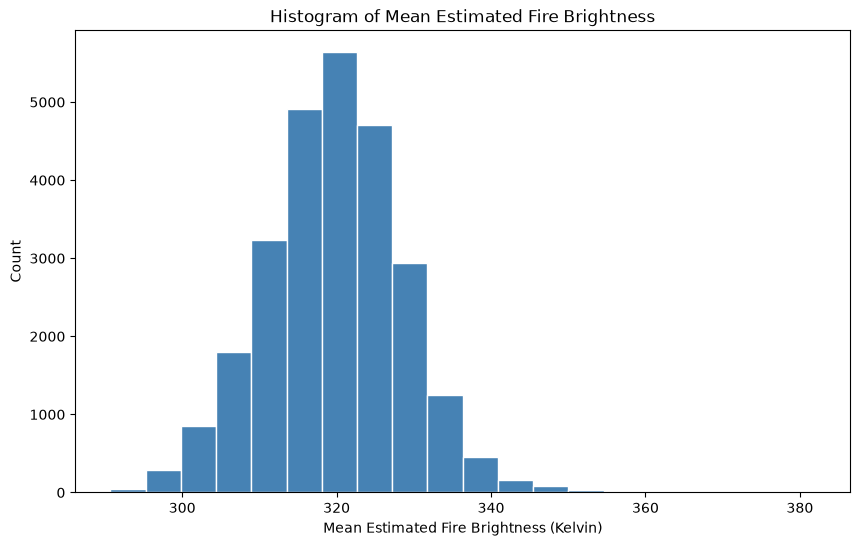

Mean / Median : 319.66 / 319.78 K


In [16]:
# TASK 1.6 - histogram of mean estimated fire brightness (Matplotlib)
plt.figure(figsize=(10, 6))
# Setting the number of bins to 20 for better visualization
plt.hist(x=df['Mean_estimated_fire_brightness'], bins=20, color='steelblue', edgecolor='white')
plt.xlabel('Mean Estimated Fire Brightness (Kelvin)')
plt.ylabel('Count')
plt.title('Histogram of Mean Estimated Fire Brightness')
plt.show()

print('Mean / Median :', round(df['Mean_estimated_fire_brightness'].mean(), 2),
      '/', round(df['Mean_estimated_fire_brightness'].median(), 2), 'K')

<details>
    <summary>Click here for Solution</summary>

```python
# Creating a histogram to visualize the distribution of mean estimated fire brightness
plt.figure(figsize=(10, 6))
# Using plt.hist to create the histogram
# Setting the number of bins to 20 for better visualization
plt.hist(x=df['Mean_estimated_fire_brightness'], bins=20)
plt.xlabel('Mean Estimated Fire Brightness (Kelvin)')
plt.ylabel('Count')
plt.title('Histogram of Mean Estimated Fire Brightness')
plt.show()
```
</details>


### TASK 1.7: What if we need to understand the distribution of estimated fire brightness across regions? Let's use the functionality of seaborn and  pass region as hue


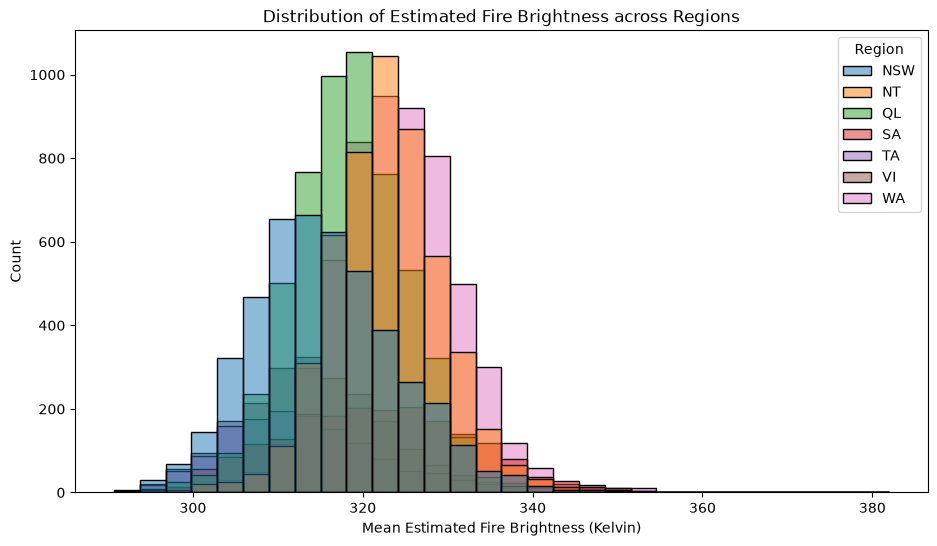

In [17]:
# TASK 1.7 (part 1) - distribution of brightness across regions, region as hue
plt.figure(figsize=(11, 6))
sns.histplot(data=df, x='Mean_estimated_fire_brightness', hue='Region', bins=30)
plt.xlabel('Mean Estimated Fire Brightness (Kelvin)')
plt.ylabel('Count')
plt.title('Distribution of Estimated Fire Brightness across Regions')
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
# Creating a histogram to visualize the distribution of mean estimated fire brightness across regions using Seaborn
# Using sns.histplot to create the histogram
# Specifying the DataFrame (data=df) and the column for the x-axis (x='Mean_estimated_fire_brightness')
# Adding hue='Region' to differentiate the distribution across regions
sns.histplot(data=df, x='Mean_estimated_fire_brightness', hue='Region')
plt.show()
```
</details>


### looks better!, now include the parameter `multiple='stack'` in the histplot() and see the difference. Include labels and titles as well


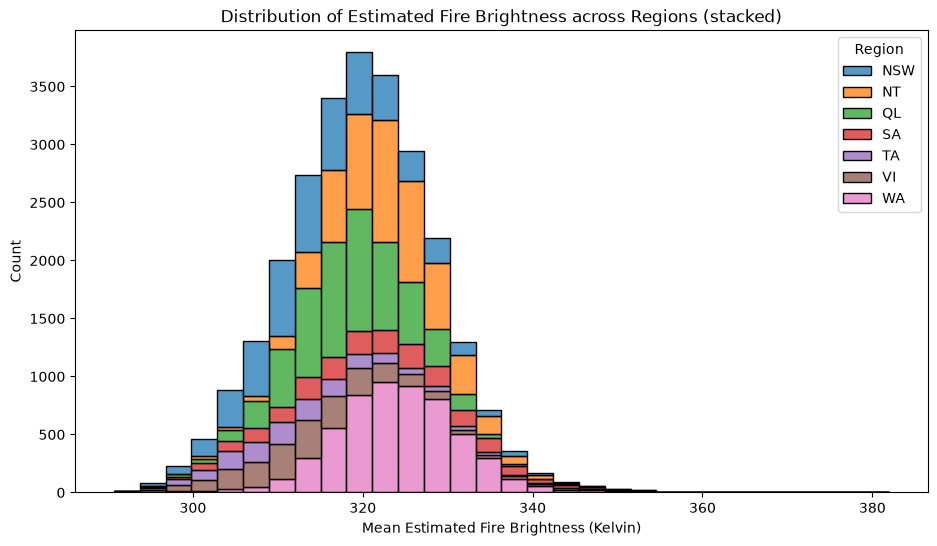

In [18]:
# TASK 1.7 (part 2) - same plot with multiple='stack'
plt.figure(figsize=(11, 6))
sns.histplot(data=df, x='Mean_estimated_fire_brightness', hue='Region',
             multiple='stack', bins=30)
plt.xlabel('Mean Estimated Fire Brightness (Kelvin)')
plt.ylabel('Count')
plt.title('Distribution of Estimated Fire Brightness across Regions (stacked)')
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
# Creating a stacked histogram to visualize the distribution of mean estimated fire brightness across regions using Seaborn
# Using sns.histplot to create the stacked histogram
# Specifying the DataFrame (data=df) and the column for the x-axis (x='Mean_estimated_fire_brightness')
# Adding hue='Region' to differentiate the distribution across regions
# Setting multiple='stack' to stack the histograms for different regions
sns.histplot(data=df, x='Mean_estimated_fire_brightness', hue='Region', multiple='stack')
plt.show()
```
</details>


---


### TASK 1.8: Let's try to find if there is any correlation between mean estimated fire radiative power and mean confidence level?


<details>
    <summary>Click here for a Hint</summary>
    Call plt.scatter() <br> or use the sns.scatterplot()
</details>


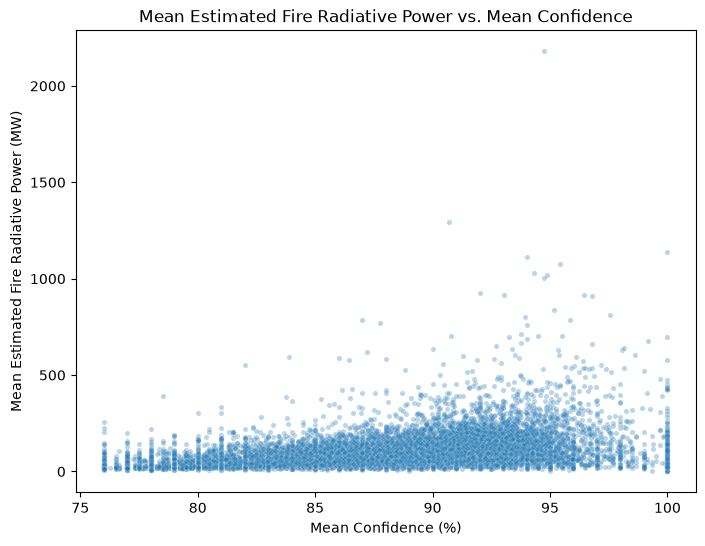

                                     Mean_confidence  \
Mean_confidence                               1.0000   
Mean_estimated_fire_radiative_power           0.4523   

                                     Mean_estimated_fire_radiative_power  
Mean_confidence                                                   0.4523  
Mean_estimated_fire_radiative_power                               1.0000  


In [19]:
# TASK 1.8 - correlation between mean estimated fire radiative power
# and mean confidence level
df_new = df[['Mean_confidence', 'Mean_estimated_fire_radiative_power']].dropna()

plt.figure(figsize=(8, 6))
# Using sns.scatterplot to create the scatter plot
sns.scatterplot(data=df_new, x='Mean_confidence',
                y='Mean_estimated_fire_radiative_power', s=14, alpha=0.3)
plt.xlabel('Mean Confidence (%)')
plt.ylabel('Mean Estimated Fire Radiative Power (MW)')
plt.title('Mean Estimated Fire Radiative Power vs. Mean Confidence')
plt.show()

# Quantify the relationship
print(df_new.corr().round(4))

<details>
    <summary>Click here for Solution</summary>

```python
    # Creating a scatter plot to visualize the relationship between mean estimated fire radiative power and mean  confidence using Seaborn
    plt.figure(figsize=(8, 6))
    # Using sns.scatterplot to create the scatter plot
    # Specifying the DataFrame (data=df) and the columns for the x-axis (x='Mean_confidence') and y-axis            (y='Mean_estimated_fire_radiative_power')
    sns.scatterplot(data=df, x='Mean_confidence', y='Mean_estimated_fire_radiative_power')
    plt.xlabel('Mean Estimated Fire Radiative Power (MW)')
    plt.ylabel('Mean Confidence')
    plt.title('Mean Estimated Fire Radiative Power vs. Mean Confidence')
    plt.show()
```
</details>


---


### TASK 1.9: Let's mark these seven regions on the Map of Australia using Folium
<br> we have created a dataframe for you containing the regions, their latitudes and longitudes. <br> For australia use [-25, 135] as location to create the map


In [20]:
region_data = {'region':['NSW','QL','SA','TA','VI','WA','NT'], 'Lat':[-31.8759835,-22.1646782,-30.5343665,-42.035067,-36.5986096,-25.2303005,-19.491411], 
               'Lon':[147.2869493,144.5844903,135.6301212,146.6366887,144.6780052,121.0187246,132.550964]}
reg=pd.DataFrame(region_data)
reg

,region,Lat,Lon
0,NSW,-31.875984,147.286949
1,QL,-22.164678,144.584490
2,SA,-30.534367,135.630121
3,TA,-42.035067,146.636689
4,VI,-36.598610,144.678005
5,WA,-25.230300,121.018725
6,NT,-19.491411,132.550964


In [21]:
# TASK 1.9 - mark the seven regions on the map of Australia
# instantiate a feature group
aus_reg = folium.map.FeatureGroup()

# Create a Folium map centered on Australia
Aus_map = folium.Map(location=[-25, 135], zoom_start=4)

# loop through the regions and add each one to the feature group
for lat, lng, lab in zip(reg.Lat, reg.Lon, reg.region):
    aus_reg.add_child(
        folium.features.CircleMarker(
            [lat, lng],
            popup=lab,
            radius=10,
            color='red',
            fill=True,
            fill_color='red',
            fill_opacity=0.6
        )
    )

Aus_map.add_child(aus_reg)

# render the map inline (the notebook output keeps the HTML representation)
from IPython.display import HTML
HTML(Aus_map._repr_html_())

<details>
    <summary>Click here for Solution</summary>

```python
# instantiate a feature group 
aus_reg = folium.map.FeatureGroup()

# Create a Folium map centered on Australia
Aus_map = folium.Map(location=[-25, 135], zoom_start=4)

# loop through the region and add to feature group
for lat, lng, lab in zip(reg.Lat, reg.Lon, reg.region):
    aus_reg.add_child(
        folium.features.CircleMarker(
            [lat, lng],
            popup=lab,
            radius=5, # define how big you want the circle markers to be
            color='red',
            fill=True,
            fill_color='blue',
            fill_opacity=0.6
        )
    )

# add incidents to map
Aus_map.add_child(aus_reg)
```
</details>


---


# Congratulations! You have completed the lab


## Authors


[Dr. Pooja](author_link)


#### Copyright © 2023 IBM Corporation. All rights reserved.
```{toggle}## Change Log
```


```{toggle}|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
```

```{toggle}|-|-|-|-|
```
```{toggle}|2023-06-281|0.2|Dr. Pooja|Initial Lab Creation|
```
```{toggle}|2023-05-01|0.1|Shengkai|Create Lab Template|
```
